# Descomposición de las series temporales de la cartera

Descomposición del precio de Caterpillar (CAT), Merck (MRK) y Microsoft (MSFT) en tendencia, estacionalidad y residuo, con la elección del modelo y del periodo para cada activo.

- **Entrada:** `Datos/Transformados/dowjones_diario_2016_2025.csv` (precio de cierre diario)
- **Salida:** gráficos en `Graficos/` y `Datos/Transformados/descomposicion_resumen.csv`

In [ ]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf

warnings.filterwarnings("ignore", category=FutureWarning)

#Estilo común de los gráficos
RAIZ_PROYECTO = next((d for d in [Path.cwd(), *Path.cwd().parents] if (d / "packages" / "bbva_graficos.py").exists()), None)
if RAIZ_PROYECTO is None:
    raise FileNotFoundError(f"No se encuentra packages/bbva_graficos.py ni en {Path.cwd()} ni en sus carpetas superiores. "
                            "Copia la carpeta packages/ en la raíz del proyecto.")
sys.path.insert(0, str(RAIZ_PROYECTO))
from packages.bbva_graficos import BBVA, anotar_fuente, configurar_graficos, fmt_es, guardar_mpl, numeros_es
configurar_graficos(carpeta=str(RAIZ_PROYECTO / "Graficos"))

Raíz del proyecto: c:\RETOS BDATA 3\26_27_R09_Azul_Claro


In [ ]:
#Rutas y parámetros comunes

RUTA_DATOS = RAIZ_PROYECTO / "Datos" / "Transformados" / "dowjones_diario_2016_2025.csv"
RUTA_RESULTADOS = RAIZ_PROYECTO / "Datos" / "Transformados"

ACTIVOS = {"CAT": "Caterpillar", "MRK": "Merck", "MSFT": "Microsoft"}
ALFA = 0.05                 #Nivel de significación de todos los contrastes

#Colores de la paleta BBVA
PRINCIPAL, MEDIO, CIELO, AGUAMARINA, MARINO = (BBVA[k] for k in ("principal", "medio", "cielo", "agua", "marino"))
GRIS = BBVA["gris_dato"]         
FUENTE = "elaboración propia a partir de los cierres diarios del Dow Jones (2016-2025)."
pd.set_option("display.width", 200)


def eje_anios(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


def fmt_p(p):
    return "< 0,001" if p < 0.001 else f"= {fmt_es(p, 3)}"


def fmt_signo(valor, decimales=2):
    return ("+" if valor > 0 else "") + fmt_es(valor, decimales)


def pct_es(valor, decimales=0, signo=False):
    texto = fmt_signo(valor * 100, decimales) if signo else fmt_es(valor * 100, decimales)
    return f"{texto} %"


def formato_eje_pct(ax, decimales=0, signo=False):
    ax.yaxis.set_major_locator(mticker.MaxNLocator(steps=[1, 2, 5, 10]))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: pct_es(v, decimales, signo and abs(v) > 1e-12)))


def cerrar_grafico(fig, nombre):
    #Ajustes puntuales de figuras con varios paneles
    if fig._suptitle is not None:
        fig._suptitle.set(fontsize=16, fontweight="bold", color=MARINO)
        for ax in fig.axes:
            for posicion in ("left", "center", "right"):
                if ax.get_title(loc=posicion):
                    ax.set_title(ax.get_title(loc=posicion), loc=posicion, fontsize=13)
        fig.tight_layout()
    for ax in fig.axes:
        for eje in (ax.xaxis, ax.yaxis):
            if type(eje.get_major_formatter()) is mticker.ScalarFormatter:
                numeros_es(eje)
    anotar_fuente(fig, FUENTE)
    guardar_mpl(fig, nombre)
    plt.show()

## 1. Datos y frecuencia

In [3]:
df = pd.read_csv(RUTA_DATOS, parse_dates=["date"])
df = df[df["symbol"].isin(ACTIVOS)].sort_values(["symbol", "date"])
precios = df.pivot(index="date", columns="symbol", values="close")[list(ACTIVOS)]

#Espaciado entre sesiones consecutivas (días naturales)
saltos = precios.index.to_series().diff().dt.days.value_counts().sort_index()
print(f"Sesiones: {len(precios)} | de {precios.index[0].date()} a {precios.index[-1].date()}")
print("Días naturales entre sesiones consecutivas:", saltos.astype(int).to_dict())
print("Sesiones por año:", precios.groupby(precios.index.year).size().to_dict())
print("Valores ausentes por activo:", precios.isna().sum().to_dict())
print("Precio mínimo por activo (USD):", precios.min().round(2).to_dict())

#Rentabilidad diaria en los días en que cambia la fuente de los datos: un salto artificial aparecería aquí
rent_diaria = np.log(precios).diff()
for t in ACTIVOS:
    d = df[df["symbol"] == t].set_index("date")["fuente"]
    cambios = d.index[(d != d.shift()) & d.shift().notna()]
    print(f"{t}: {len(cambios)} cambios de fuente; |rentabilidad| máxima en esos días = "
          f"{rent_diaria.loc[cambios, t].abs().max():.4f} (máxima de toda la serie: {rent_diaria[t].abs().max():.4f})")

Sesiones: 2514 | de 2016-01-04 a 2025-12-31
Días naturales entre sesiones consecutivas: {1.0: 1966, 2.0: 26, 3.0: 453, 4.0: 68}
Sesiones por año: {2016: 252, 2017: 251, 2018: 251, 2019: 252, 2020: 253, 2021: 252, 2022: 251, 2023: 250, 2024: 252, 2025: 250}
Valores ausentes por activo: {'CAT': 0, 'MRK': 0, 'MSFT': 0}
Precio mínimo por activo (USD): {'CAT': 57.91, 'MRK': 46.36, 'MSFT': 48.43}
CAT: 8 cambios de fuente; |rentabilidad| máxima en esos días = 0.0195 (máxima de toda la serie: 0.1534)
MRK: 10 cambios de fuente; |rentabilidad| máxima en esos días = 0.0318 (máxima de toda la serie: 0.1038)
MSFT: 10 cambios de fuente; |rentabilidad| máxima en esos días = 0.0354 (máxima de toda la serie: 0.1595)


In [4]:
#Parámetros de esta sección
PERIODO = 12                #Periodo estacional candidato en la serie mensual (meses por año)
FREC_MES = "ME" if tuple(int(x) for x in pd.__version__.split(".")[:2]) >= (2, 2) else "M"   # fin de mes ("M" antes de pandas 2.2)

precios_mes = precios.resample(FREC_MES).last()
n_meses = len(precios_mes)
anios_completos = int((precios_mes.groupby(precios_mes.index.year).size() == 12).sum())
print(f"Observaciones mensuales: {n_meses} ({precios_mes.index[0]:%Y-%m} a {precios_mes.index[-1]:%Y-%m})")
print(f"Ciclos anuales completos: {anios_completos} (seasonal_decompose exige al menos 2)")
print(f"La media móvil centrada de {PERIODO} meses pierde {PERIODO // 2} observaciones en cada extremo: "
      f"la tendencia y el residuo se estiman en {n_meses - PERIODO} meses, y cada índice estacional es la media "
      f"de {(n_meses - PERIODO) // PERIODO} valores")
print(precios_mes.describe().round(2).to_string())

Observaciones mensuales: 120 (2016-01 a 2025-12)
Ciclos anuales completos: 10 (seasonal_decompose exige al menos 2)
La media móvil centrada de 12 meses pierde 6 observaciones en cada extremo: la tendencia y el residuo se estiman en 108 meses, y cada índice estacional es la media de 9 valores
symbol     CAT     MRK    MSFT
count   120.00  120.00  120.00
mean    205.93   81.20  230.72
std     111.65   20.73  139.23
min      62.24   47.91   49.87
25%     126.94   62.85  100.89
50%     176.13   77.68  228.57
75%     247.22   93.89  332.69
max     577.26  131.95  533.50


ANÁLISIS:

Hay 2.514 sesiones por activo, sin valores ausentes y con todos los precios positivos (mínimo de 46,36 USD). En los días en que cambia la fuente de los datos la rentabilidad no supera el 3,5 %, muy lejos de los máximos de cada serie (10-16 %), así que no hay saltos artificiales.

Cada año tiene entre 250 y 253 sesiones, por lo que un periodo anual fijo sobre la serie diaria se iría desplazando. Por eso se descompone la serie mensual (último cierre de cada mes): 120 meses y 10 ciclos anuales completos, suficientes para `seasonal_decompose` (mínimo 2). Cada índice estacional se estima con 9 valores.

## 2. Modelo: aditivo o multiplicativo

Dos criterios por activo: la correlación de Spearman entre el precio medio de cada año y la desviación típica de sus variaciones mensuales en USD, y la correlación entre la tendencia y el tamaño del residuo con cada modelo. Si la amplitud crece con el nivel, el modelo es multiplicativo (exige precios positivos).

In [5]:
def amplitud_por_anio(serie_mensual):
    #Nivel medio y desviación típica de las variaciones mensuales (USD) de cada año natural
    return pd.DataFrame({
        "nivel_usd": serie_mensual.groupby(serie_mensual.index.year).mean(),
        "amplitud_usd": serie_mensual.diff().groupby(serie_mensual.index.year).std(),
    })


def residuo_relativo(descomposicion, modelo):
    #Tamaño del residuo comparable entre modelos: en USD (aditivo) o en desviación porcentual (multiplicativo)
    return descomposicion.resid.abs() if modelo == "additive" else (descomposicion.resid - 1).abs()


def elegir_modelo(serie_mensual):
    resultado = {"precio_min_usd": serie_mensual.min(),
                 "max_entre_min": serie_mensual.max() / serie_mensual.min()}
    if serie_mensual.min() <= 0:
        resultado.update(modelo="additive", decision="Solo es posible el aditivo (hay valores <= 0)")
        return resultado

    #Criterio 1: amplitud frente a nivel, por años
    anual = amplitud_por_anio(serie_mensual)
    rho1, p1 = stats.spearmanr(anual["nivel_usd"], anual["amplitud_usd"])
    resultado.update(rho_amplitud_nivel=rho1, p_amplitud_nivel=p1)

    #Criterio 2: dependencia del tamaño del residuo respecto a la tendencia, con cada modelo
    for modelo, sufijo in [("additive", "aditivo"), ("multiplicative", "multiplicativo")]:
        d = seasonal_decompose(serie_mensual, model=modelo, period=PERIODO)
        datos = pd.DataFrame({"tendencia": d.trend, "residuo": residuo_relativo(d, modelo)}).dropna()
        rho, p = stats.spearmanr(datos["tendencia"], datos["residuo"])
        resultado.update({f"rho_resid_{sufijo}": rho, f"p_resid_{sufijo}": p})

    crece_1 = (rho1 > 0) and (p1 < ALFA)
    crece_2 = (resultado["rho_resid_aditivo"] > 0) and (resultado["p_resid_aditivo"] < ALFA)
    if crece_1 and crece_2:
        modelo, decision = "multiplicative", "Multiplicativo: los dos criterios indican que la amplitud crece con el nivel"
    elif not crece_1 and not crece_2:
        modelo, decision = "additive", "Aditivo: ningún criterio indica que la amplitud crezca con el nivel"
    else:
        mejor = abs(resultado["rho_resid_multiplicativo"]) < abs(resultado["rho_resid_aditivo"])
        modelo = "multiplicative" if mejor else "additive"
        decision = f"{'Multiplicativo' if mejor else 'Aditivo'} (evidencia parcial: solo un criterio es significativo)"
    resultado.update(modelo=modelo, decision=decision)
    return resultado


eleccion_modelo = pd.DataFrame({t: elegir_modelo(precios_mes[t]) for t in ACTIVOS}).T
MODELO = eleccion_modelo["modelo"].to_dict()
columnas = ["precio_min_usd", "max_entre_min", "rho_amplitud_nivel", "p_amplitud_nivel",
            "rho_resid_aditivo", "p_resid_aditivo", "rho_resid_multiplicativo", "p_resid_multiplicativo"]
print(eleccion_modelo[columnas].astype(float).round(3).to_string())
print()
for t in ACTIVOS:
    print(f"{t}: {eleccion_modelo.loc[t, 'decision']}")
for t in ACTIVOS:
    print(f"\n{t}: nivel y amplitud por año (USD)")
    print(amplitud_por_anio(precios_mes[t]).round(1).T.to_string())

      precio_min_usd  max_entre_min  rho_amplitud_nivel  p_amplitud_nivel  rho_resid_aditivo  p_resid_aditivo  rho_resid_multiplicativo  p_resid_multiplicativo
CAT            62.24          9.275               0.952             0.000              0.500            0.000                     0.271                   0.005
MRK            47.91          2.754               0.697             0.025              0.329            0.001                     0.143                   0.139
MSFT           49.87         10.698               0.939             0.000              0.420            0.000                     0.264                   0.006

CAT: Multiplicativo: los dos criterios indican que la amplitud crece con el nivel
MRK: Multiplicativo: los dos criterios indican que la amplitud crece con el nivel
MSFT: Multiplicativo: los dos criterios indican que la amplitud crece con el nivel

CAT: nivel y amplitud por año (USD)
date          2016   2017   2018   2019   2020   2021   2022   2023   2024 

Guardado: c:\RETOS BDATA 3\26_27_R09_Azul_Claro\Graficos\descomposicion_01_amplitud_frente_a_nivel.png


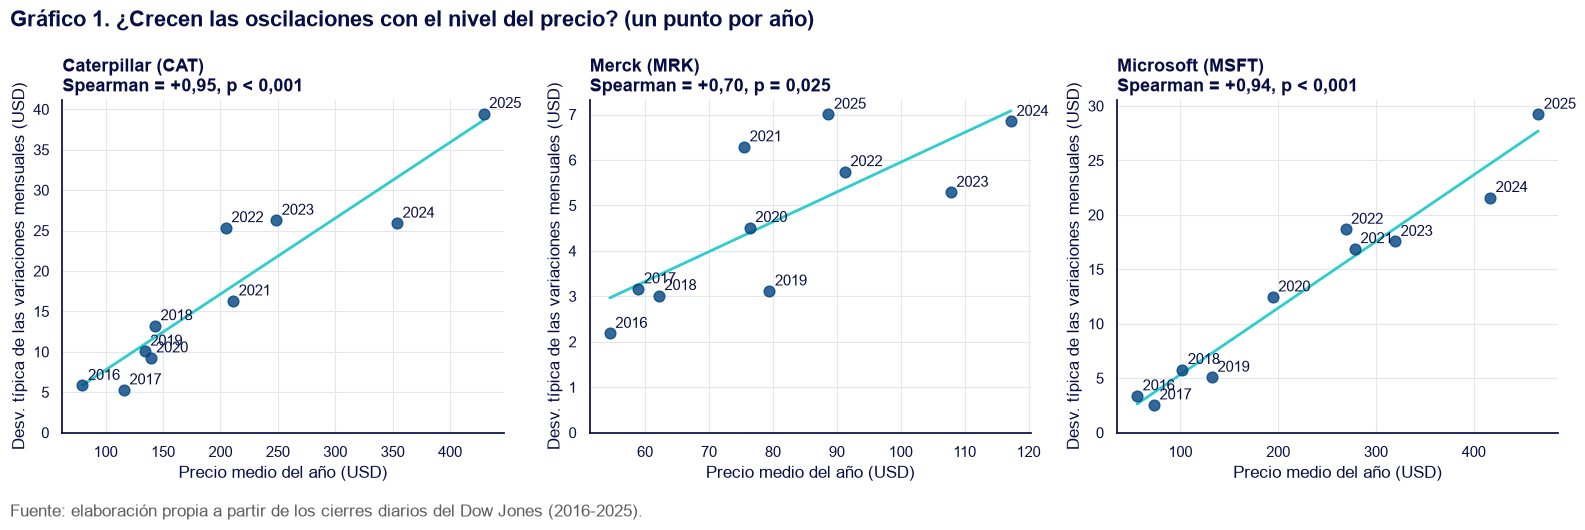

In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 5))
for ax, t in zip(ejes, ACTIVOS):
    anual = amplitud_por_anio(precios_mes[t])
    ax.scatter(anual["nivel_usd"], anual["amplitud_usd"], s=60, color=PRINCIPAL, alpha=0.8, zorder=3)
    for anio, fila in anual.iterrows():
        ax.annotate(str(anio), (fila["nivel_usd"], fila["amplitud_usd"]), xytext=(4, 4),
                    textcoords="offset points", color=MARINO, fontsize=11)
    pendiente, corte = np.polyfit(anual["nivel_usd"], anual["amplitud_usd"], 1)
    x = np.linspace(anual["nivel_usd"].min(), anual["nivel_usd"].max(), 50)
    ax.plot(x, corte + pendiente * x, color=AGUAMARINA, lw=2)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Precio medio del año (USD)")
    ax.set_ylabel("Desv. típica de las variaciones mensuales (USD)")
    rho = eleccion_modelo.loc[t, "rho_amplitud_nivel"]
    p = eleccion_modelo.loc[t, "p_amplitud_nivel"]
    ax.set_title(f"{ACTIVOS[t]} ({t})\nSpearman = {fmt_signo(rho, 2)}, p {fmt_p(p)}")
fig.suptitle("Gráfico 1. ¿Crecen las oscilaciones con el nivel del precio? (un punto por año)", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "descomposicion_01_amplitud_frente_a_nivel")

ANÁLISIS:

En los tres activos la amplitud de las oscilaciones crece con el precio, así que se usa el modelo **multiplicativo**:

- **Caterpillar y Microsoft:** casos claros. Su precio máximo es 9,3 y 10,7 veces el mínimo, y la desviación típica de las variaciones mensuales pasa de 5,8 a 39,5 USD y de 3,4 a 29,2 USD (Spearman 0,95 y 0,94; p < 0,001). Con el modelo aditivo el residuo crece con la tendencia (ρ = 0,50 y 0,42); con el multiplicativo esa relación baja a 0,27 y 0,26.
- **Merck:** evidencia más débil. Su precio solo varía 2,8 veces y la relación es menor (ρ = 0,70; p = 0,025); en 2025 el nivel baja sin que baje la amplitud. La elección se apoya sobre todo en el residuo: con el modelo aditivo depende de la tendencia (ρ = 0,33; p = 0,001) y con el multiplicativo no (ρ = 0,14; p = 0,139).

## 3. Periodo y estacionalidad

Con datos mensuales el periodo candidato es 12 meses. Antes se descarta el efecto semanal en la serie diaria. La estacionalidad anual se contrasta con la autocorrelación en los retardos 12, 24 y 36, el test de Kruskal-Wallis por mes, la estabilidad del patrón entre 2016-2020 y 2021-2025, y la fuerza estacional F_S.

In [7]:
#Periodo semanal, sobre la serie diaria
NOMBRES_DIA = ["Lun", "Mar", "Mié", "Jue", "Vie"]
filas = {}
for t in ACTIVOS:
    r = rent_diaria[t].dropna()
    grupos = [g.to_numpy() for _, g in r.groupby(r.index.dayofweek)]
    acf_diaria = acf(r, nlags=5, fft=True)
    filas[t] = {"kruskal_dia_p": stats.kruskal(*grupos).pvalue,
                "acf_retardo_5": acf_diaria[5], "banda_95": 1.96 / np.sqrt(len(r))}
semanal = pd.DataFrame(filas).T
print("Estacionalidad semanal en la rentabilidad diaria:")
print(semanal.round(3).to_string())

Estacionalidad semanal en la rentabilidad diaria:
      kruskal_dia_p  acf_retardo_5  banda_95
CAT           0.853          0.006     0.039
MRK           0.354          0.023     0.039
MSFT          0.841          0.017     0.039


In [8]:
#Parámetros de esta sección
RETARDOS_ACF = 36           #3 años de retardos en los correlogramas mensuales

#Periodo anual, sobre la serie mensual
def fuerza_estacional(descomposicion, modelo):
    #Fuerza de Hyndman. En el multiplicativo se calcula sobre los logaritmos de los componentes
    s, r = descomposicion.seasonal, descomposicion.resid
    if modelo == "multiplicative":
        s, r = np.log(s), np.log(r)
    datos = pd.DataFrame({"s": s, "r": r}).dropna()
    return max(0.0, 1 - datos["r"].var() / (datos["s"] + datos["r"]).var())


def indices_estacionales(serie_mensual, modelo):
    #Índice estacional de cada mes del calendario
    d = seasonal_decompose(serie_mensual, model=modelo, period=PERIODO)
    return d.seasonal.groupby(d.seasonal.index.month).first()


descomposiciones, evidencia, serie_sin_tendencia, rent_mes = {}, {}, {}, {}
for t in ACTIVOS:
    s = precios_mes[t]
    d = seasonal_decompose(s, model=MODELO[t], period=PERIODO)
    descomposiciones[t] = d
    serie_sin_tendencia[t] = (s / d.trend - 1 if MODELO[t] == "multiplicative" else s - d.trend).dropna()
    rent_mes[t] = np.log(s).diff().dropna()

    acf_sin_tendencia = acf(serie_sin_tendencia[t], nlags=RETARDOS_ACF, fft=True)
    acf_rent = acf(rent_mes[t], nlags=RETARDOS_ACF, fft=True)
    kruskal = stats.kruskal(*[g.to_numpy() for _, g in rent_mes[t].groupby(rent_mes[t].index.month)])
    mitad_1 = indices_estacionales(s[:"2020"], MODELO[t])
    mitad_2 = indices_estacionales(s["2021":], MODELO[t])
    rho_estab, p_estab = stats.spearmanr(mitad_1, mitad_2)

    significativo_kw = kruskal.pvalue < ALFA
    estable = (rho_estab > 0) and (p_estab < ALFA)
    if significativo_kw and estable:
        veredicto = "Significativa"
    elif significativo_kw or estable:
        veredicto = "Débil, no concluyente"
    else:
        veredicto = "No hay evidencia"

    evidencia[t] = {
        "acf_sin_tend_12": acf_sin_tendencia[12], "acf_sin_tend_24": acf_sin_tendencia[24],
        "acf_rent_12": acf_rent[12], "acf_rent_24": acf_rent[24], "acf_rent_36": acf_rent[36],
        "banda_95_rent": 1.96 / np.sqrt(len(rent_mes[t])),
        "kruskal_mes_H": kruskal.statistic, "kruskal_mes_p": kruskal.pvalue,
        "estabilidad_rho": rho_estab, "estabilidad_p": p_estab,
        "fuerza_estacional_FS": fuerza_estacional(d, MODELO[t]),
        "amplitud_estacional": (d.seasonal.max() - d.seasonal.min()),
        "veredicto": veredicto,
    }

evidencia = pd.DataFrame(evidencia).T
print(evidencia.drop(columns="veredicto").astype(float).round(3).to_string())
print()
print(evidencia["veredicto"].to_string())

      acf_sin_tend_12  acf_sin_tend_24  acf_rent_12  acf_rent_24  acf_rent_36  banda_95_rent  kruskal_mes_H  kruskal_mes_p  estabilidad_rho  estabilidad_p  fuerza_estacional_FS  amplitud_estacional
CAT            -0.232            0.086       -0.159       -0.061        0.048           0.18         11.884          0.372            0.664          0.018                 0.107                0.080
MRK            -0.048           -0.064       -0.073        0.036       -0.047           0.18         11.554          0.398           -0.811          0.001                 0.026                0.034
MSFT           -0.157            0.087        0.074        0.035       -0.143           0.18         14.529          0.205            0.203          0.527                 0.105                0.048

CAT     Débil, no concluyente
MRK          No hay evidencia
MSFT         No hay evidencia


Guardado: c:\RETOS BDATA 3\26_27_R09_Azul_Claro\Graficos\descomposicion_02_correlogramas_periodo.png


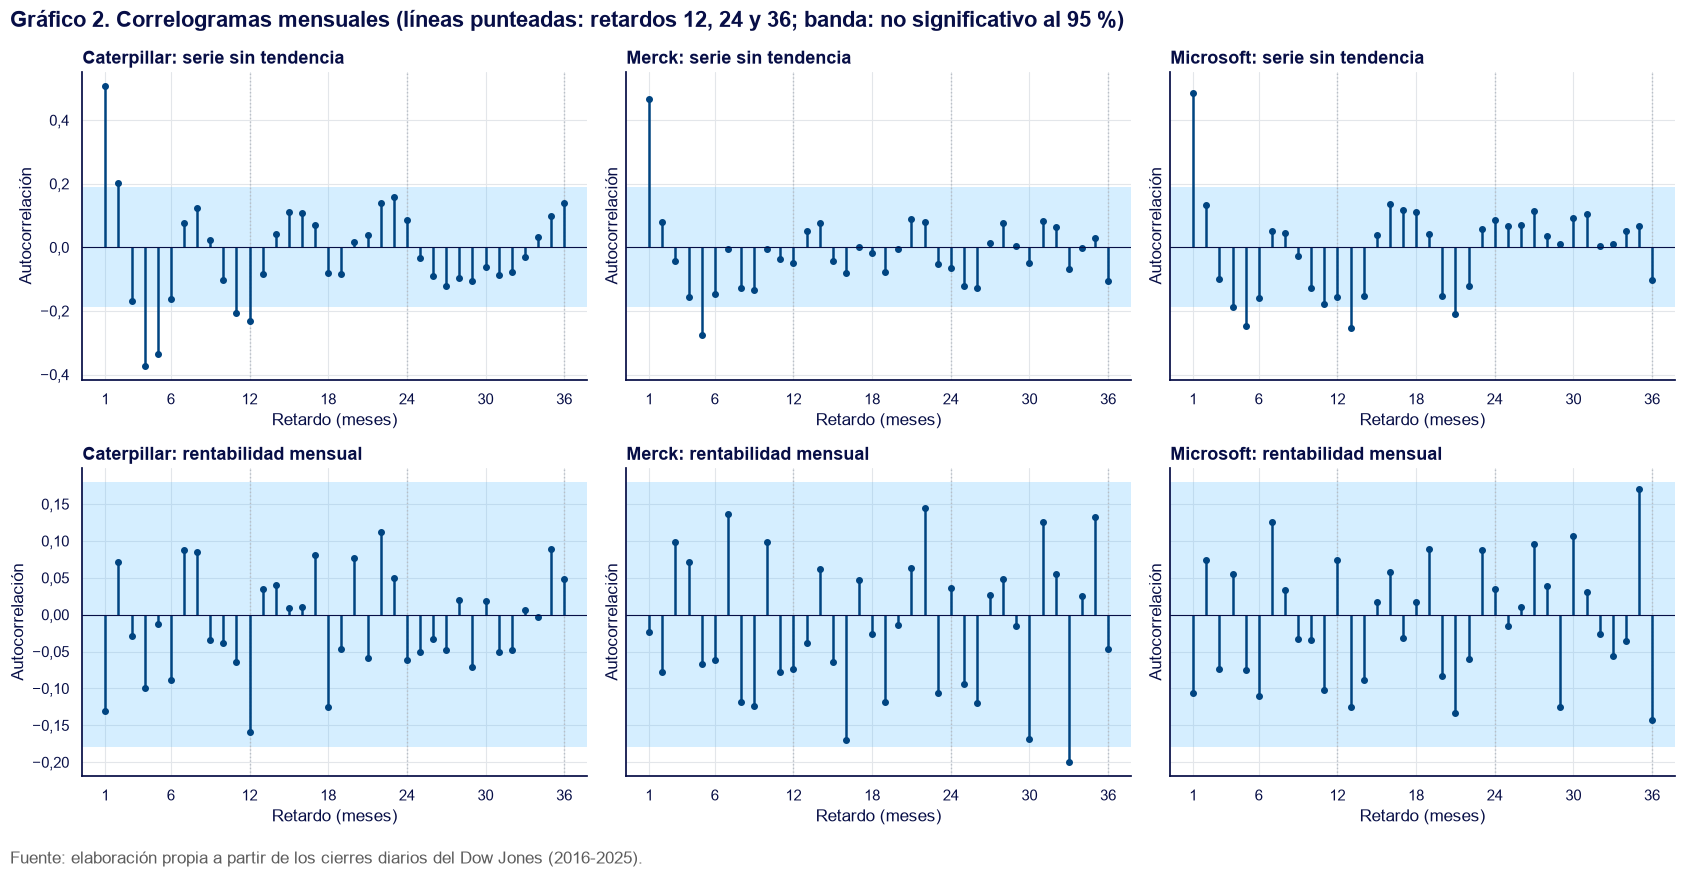

In [9]:
def dibujar_correlograma(ax, valores, n, titulo):
    retardos = np.arange(1, len(valores))
    banda = 1.96 / np.sqrt(n)
    ax.axhspan(-banda, banda, color=CIELO, alpha=0.25, lw=0)
    for anual in (12, 24, 36):
        ax.axvline(anual, color=GRIS, lw=1, ls=":")
    ax.vlines(retardos, 0, valores[1:], color=PRINCIPAL, lw=1.8)
    ax.plot(retardos, valores[1:], "o", ms=4, color=PRINCIPAL)
    ax.axhline(0, color=MARINO, lw=0.8)
    ax.set_xticks([1, 6, 12, 18, 24, 30, 36])
    ax.set_xlabel("Retardo (meses)")
    ax.set_ylabel("Autocorrelación")
    ax.set_title(titulo)


fig, ejes = plt.subplots(2, 3, figsize=(17, 8.5), sharey="row")
for col, t in enumerate(ACTIVOS):
    dibujar_correlograma(ejes[0, col], acf(serie_sin_tendencia[t], nlags=RETARDOS_ACF, fft=True),
                         len(serie_sin_tendencia[t]), f"{ACTIVOS[t]}: serie sin tendencia")
    dibujar_correlograma(ejes[1, col], acf(rent_mes[t], nlags=RETARDOS_ACF, fft=True),
                         len(rent_mes[t]), f"{ACTIVOS[t]}: rentabilidad mensual")
fig.suptitle("Gráfico 2. Correlogramas mensuales (líneas punteadas: retardos 12, 24 y 36; banda: no significativo al 95 %)",
             x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "descomposicion_02_correlogramas_periodo")

Guardado: c:\RETOS BDATA 3\26_27_R09_Azul_Claro\Graficos\descomposicion_03_perfil_estacional.png


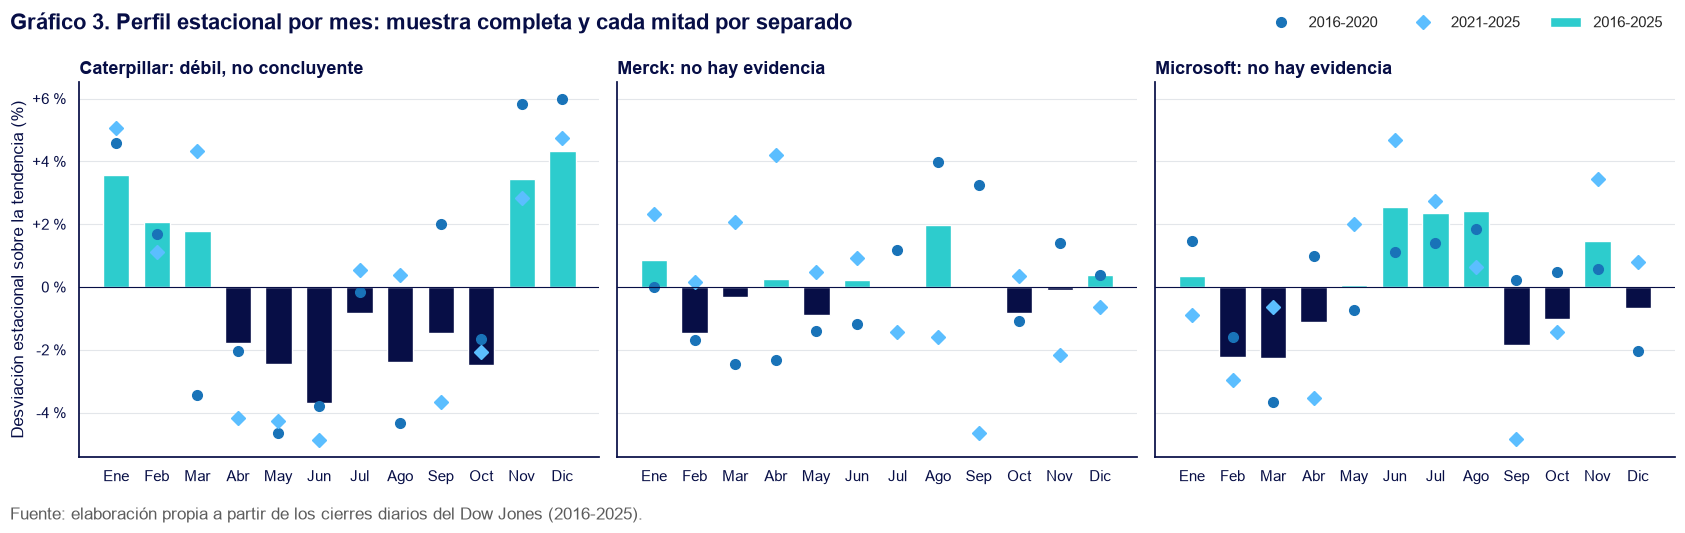

In [10]:
#Perfil estacional: índice de cada mes del calendario en toda la muestra y en cada mitad
NOMBRES_MES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
fig, ejes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, t in zip(ejes, ACTIVOS):
    base = 1 if MODELO[t] == "multiplicative" else 0
    total = indices_estacionales(precios_mes[t], MODELO[t]) - base
    ax.bar(range(12), total, color=np.where(total >= 0, AGUAMARINA, MARINO), width=0.65, label="2016-2025")
    for periodo, marcador, color in [(("2016", "2020"), "o", MEDIO), (("2021", "2025"), "D", CIELO)]:
        parcial = indices_estacionales(precios_mes[t][periodo[0]:periodo[1]], MODELO[t]) - base
        ax.plot(range(12), parcial, marcador, color=color, ms=7, label=f"{periodo[0]}-{periodo[1]}")
    ax.axhline(0, color=MARINO, lw=0.8)
    ax.set_xticks(range(12), NOMBRES_MES)
    ax.grid(axis="x", visible=False)
    formato_eje_pct(ax, decimales=0, signo=True)
    veredicto = evidencia.loc[t, "veredicto"].lower()
    ax.set_title(f"{ACTIVOS[t]}: {veredicto}")
ejes[0].set_ylabel("Desviación estacional sobre la tendencia (%)")
manejadores, etiquetas = ejes[0].get_legend_handles_labels()
fig.legend(manejadores, etiquetas, loc="upper right", bbox_to_anchor=(0.99, 1.0), ncol=3)
fig.suptitle("Gráfico 3. Perfil estacional por mes: muestra completa y cada mitad por separado", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "descomposicion_03_perfil_estacional")

ANÁLISIS:

No hay efecto semanal en ningún activo (Kruskal-Wallis por día p = 0,85, 0,35 y 0,84). Se usa el periodo de 12 meses, pero ninguno de los tres tiene una estacionalidad anual sólida:

| | Caterpillar | Merck | Microsoft |
|---|---|---|---|
| Autocorrelación en el retardo 12 | −0,23 | −0,05 | −0,16 |
| Kruskal-Wallis por mes (p) | 0,37 | 0,40 | 0,21 |
| Estabilidad entre mitades (ρ; p) | +0,66; 0,018 | −0,81; 0,001 | +0,20; 0,527 |
| Fuerza estacional F_S | 0,11 | 0,03 | 0,11 |
| Conclusión | Débil, no concluyente | No hay evidencia | No hay evidencia |

En el gráfico 2 ninguna autocorrelación es positiva y significativa en los retardos 12, 24 o 36, y ningún mes tiene una rentabilidad distinta del resto. En el gráfico 3, Caterpillar es el único activo cuyo patrón se repite en las dos mitades (por encima de la tendencia de noviembre a marzo y por debajo de abril a octubre), pero las demás pruebas no lo confirman. En Merck el patrón se invierte entre mitades, lo que indica que es ruido.

## 4. Tendencia y residuo de cada activo

Evolución de la tendencia y diagnóstico del residuo (dispersión, autocorrelación y test de Ljung-Box con 12 retardos).

In [11]:
#Parámetros de esta sección
RETARDOS_LJUNG_BOX = 12     #1 año de retardos en el test de Ljung-Box del residuo


def ljung_box(serie, retardos):
    x = serie.dropna().to_numpy()
    n = len(x)
    rho = acf(x, nlags=retardos, fft=True)[1:]
    q = n * (n + 2) * np.sum(rho ** 2 / (n - np.arange(1, retardos + 1)))
    return q, stats.chi2.sf(q, retardos)


diagnostico, extremos = {}, {}
for t in ACTIVOS:
    d = descomposiciones[t]
    residuo = (d.resid - 1 if MODELO[t] == "multiplicative" else d.resid).dropna()
    q, p = ljung_box(residuo, RETARDOS_LJUNG_BOX)
    diagnostico[t] = {"n_residuos": len(residuo), "desv_tipica": residuo.std(),
                      "acf_retardo_1": acf(residuo, nlags=1, fft=True)[1],
                      "ljung_box_Q": q, "ljung_box_p": p}
    extremos[t] = residuo.reindex(residuo.abs().sort_values(ascending=False).index[:5])
    print(f"{t}: desviación típica del residuo por año")
    print(residuo.groupby(residuo.index.year).std().round(4).to_string())
    print()

diagnostico = pd.DataFrame(diagnostico).T
print("Diagnóstico del residuo (multiplicativo: en tanto por uno):")
print(diagnostico.astype(float).round(4).to_string())
for t in ACTIVOS:
    print(f"\n{t}: cinco residuos más extremos")
    print(extremos[t].round(4).to_string())

CAT: desviación típica del residuo por año
date
2016    0.0339
2017    0.0443
2018    0.0697
2019    0.0654
2020    0.0389
2021    0.0915
2022    0.1017
2023    0.0989
2024    0.0595
2025    0.0645

MRK: desviación típica del residuo por año
date
2016    0.0392
2017    0.0489
2018    0.0465
2019    0.0397
2020    0.0430
2021    0.0552
2022    0.0695
2023    0.0572
2024    0.0530
2025    0.0593

MSFT: desviación típica del residuo por año
date
2016    0.0175
2017    0.0319
2018    0.0560
2019    0.0403
2020    0.0466
2021    0.0615
2022    0.0581
2023    0.0636
2024    0.0399
2025    0.0686

Diagnóstico del residuo (multiplicativo: en tanto por uno):
      n_residuos  desv_tipica  acf_retardo_1  ljung_box_Q  ljung_box_p
CAT        108.0       0.0779         0.4884      96.4674          0.0
MRK        108.0       0.0534         0.4811      46.1910          0.0
MSFT       108.0       0.0518         0.5041      66.8156          0.0

CAT: cinco residuos más extremos
date
2022-09-30   -0.220

In [12]:
#Evolución de la tendencia: crecimiento total, tasa anual compuesta y máximos y mínimos
evolucion = {}
for t in ACTIVOS:
    tendencia = descomposiciones[t].trend.dropna()
    anios = (tendencia.index[-1] - tendencia.index[0]).days / 365.25
    evolucion[t] = {
        "inicio": f"{tendencia.index[0]:%Y-%m}", "tendencia_inicio": tendencia.iloc[0],
        "fin": f"{tendencia.index[-1]:%Y-%m}", "tendencia_fin": tendencia.iloc[-1],
        "multiplica_por": tendencia.iloc[-1] / tendencia.iloc[0],
        "crecimiento_anual": (tendencia.iloc[-1] / tendencia.iloc[0]) ** (1 / anios) - 1,
        "maximo": f"{tendencia.idxmax():%Y-%m}", "tendencia_max": tendencia.max(),
        "caida_desde_max": tendencia.iloc[-1] / tendencia.max() - 1,
    }
    print(f"{t}: tendencia media por año (USD)")
    print(tendencia.groupby(tendencia.index.year).mean().round(1).to_string())
    print()
evolucion = pd.DataFrame(evolucion).T
print(evolucion.to_string())

CAT: tendencia media por año (USD)
date
2016     86.7
2017    116.6
2018    141.5
2019    131.9
2020    147.1
2021    205.5
2022    206.6
2023    254.5
2024    341.6
2025    387.9

MRK: tendencia media por año (USD)
date
2016     57.2
2017     58.5
2018     62.7
2019     78.0
2020     76.7
2021     76.6
2022     91.4
2023    109.7
2024    113.0
2025     90.8

MSFT: tendencia media por año (USD)
date
2016     59.0
2017     73.9
2018    101.3
2019    134.0
2020    194.9
2021    272.5
2022    275.6
2023    322.3
2024    408.5
2025    445.8

       inicio tendencia_inicio      fin tendencia_fin multiplica_por crecimiento_anual   maximo tendencia_max caida_desde_max
CAT   2016-07        81.205833  2025-06     420.47875       5.177938          0.202575  2025-06     420.47875             0.0
MRK   2016-07        54.930025  2025-06     88.448334         1.6102           0.05489  2024-04    118.132499       -0.251279
MSFT  2016-07        56.173333  2025-06    463.415835       8.249748          

## 5. Descomposición de cada activo

Modelo multiplicativo y periodo de 12 meses. La estacionalidad y el residuo se muestran como desviación porcentual sobre la tendencia, en la misma escala.

In [13]:
def grafico_descomposicion(t, numero):
    d = descomposiciones[t]
    multiplicativo = MODELO[t] == "multiplicative"
    estacional = d.seasonal - 1 if multiplicativo else d.seasonal
    residuo = d.resid - 1 if multiplicativo else d.resid
    ev = evidencia.loc[t]
    nombre_modelo = "multiplicativa" if multiplicativo else "aditiva"

    fig, ejes = plt.subplots(4, 1, figsize=(13, 12), sharex=True, gridspec_kw={"height_ratios": [1.2, 1.2, 1, 1]})
    ejes[0].plot(d.observed, color=MARINO, lw=1.8)
    ejes[0].set_ylabel("Precio (USD)")
    ejes[0].set_title("1. Serie original: precio de cierre a fin de mes")

    ejes[1].plot(d.trend, color=PRINCIPAL, lw=2.2)
    ejes[1].set_ylabel("Precio (USD)")
    ejes[1].set_title("2. Tendencia: media móvil centrada de 12 meses")

    ejes[2].plot(estacional, color=AGUAMARINA, lw=1.8, marker="o", ms=3)
    ejes[2].axhline(0, color=MARINO, lw=0.8)
    ejes[2].set_title(f"3. Estacionalidad (periodo 12 meses): {ev['veredicto'].lower()} "
                      f"(F_S = {fmt_es(ev['fuerza_estacional_FS'], 2)}; Kruskal-Wallis p = {fmt_es(ev['kruskal_mes_p'], 2)})")

    ejes[3].vlines(residuo.index, 0, residuo, color=MEDIO, lw=2.5)
    ejes[3].axhline(0, color=MARINO, lw=0.8)
    ejes[3].set_title("4. Residuo: lo que no explican la tendencia ni la estacionalidad")

    limite = np.nanmax(np.abs(np.concatenate([estacional.to_numpy(), residuo.dropna().to_numpy()]))) * 1.1
    for ax in ejes[2:]:
        ax.set_ylim(-limite, limite)
        if multiplicativo:
            formato_eje_pct(ax, decimales=0, signo=True)
            ax.set_ylabel("Desviación (%)")
        else:
            ax.set_ylabel("USD")
    eje_anios(ejes[-1])
    ejes[-1].set_xlabel("Año")
    fig.suptitle(f"Gráfico {numero}. Descomposición {nombre_modelo} de {ACTIVOS[t]} ({t}), 2016-2025",
                 x=0.01, ha="left")
    plt.tight_layout()
    cerrar_grafico(fig, f"descomposicion_{numero:02d}_{t.lower()}")

Guardado: c:\RETOS BDATA 3\26_27_R09_Azul_Claro\Graficos\descomposicion_04_cat.png


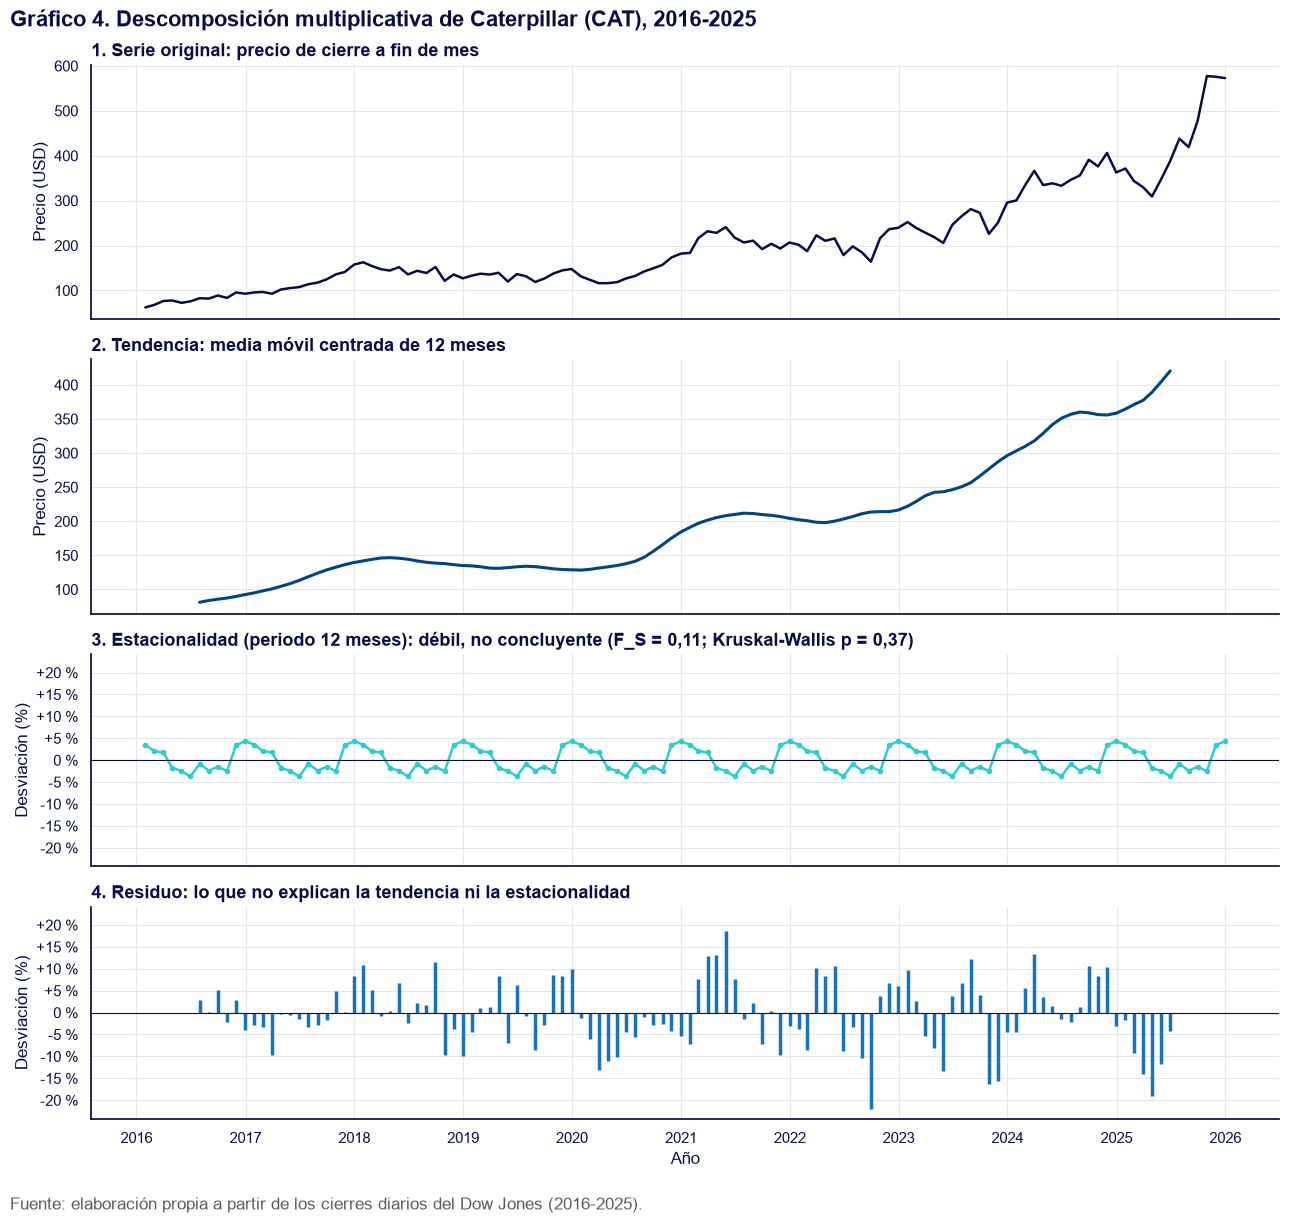

In [14]:
grafico_descomposicion("CAT", 4)

ANÁLISIS:

**Tendencia.** Pasa de 81,2 USD (julio de 2016) a 420,5 USD (junio de 2025): se multiplica por 5,2, un 20,3 % anual. Avanza a saltos: sube hasta 146,6 USD en abril de 2018, se estanca hasta enero de 2020 (128,4 USD), sube con fuerza hasta 211,8 USD en julio de 2021, tiene otra meseta hasta 2022 y acelera desde finales de 2022 hasta su máximo.

**Estacionalidad.** Débil: diciembre +4,3 % y junio −3,7 % sobre la tendencia, una oscilación de ±4 % frente a un residuo típico del 7,8 %. No es fiable para predecir.

**Residuo.** Es el mayor de los tres (desviación típica del 7,8 %; el 18 % de los meses supera el 10 %). Los meses más extremos son septiembre de 2022 (−22,0 %), abril de 2025 (−19,1 %) y mayo de 2021 (+18,7 %). No es ruido blanco (autocorrelación de 0,49 en el retardo 1; Ljung-Box p < 0,001): conserva movimientos de varios meses que la media móvil no recoge.

**Límites.** La tendencia no cubre los seis últimos meses, que son los de mayor subida (577 USD en octubre de 2025).

Guardado: c:\RETOS BDATA 3\26_27_R09_Azul_Claro\Graficos\descomposicion_05_mrk.png


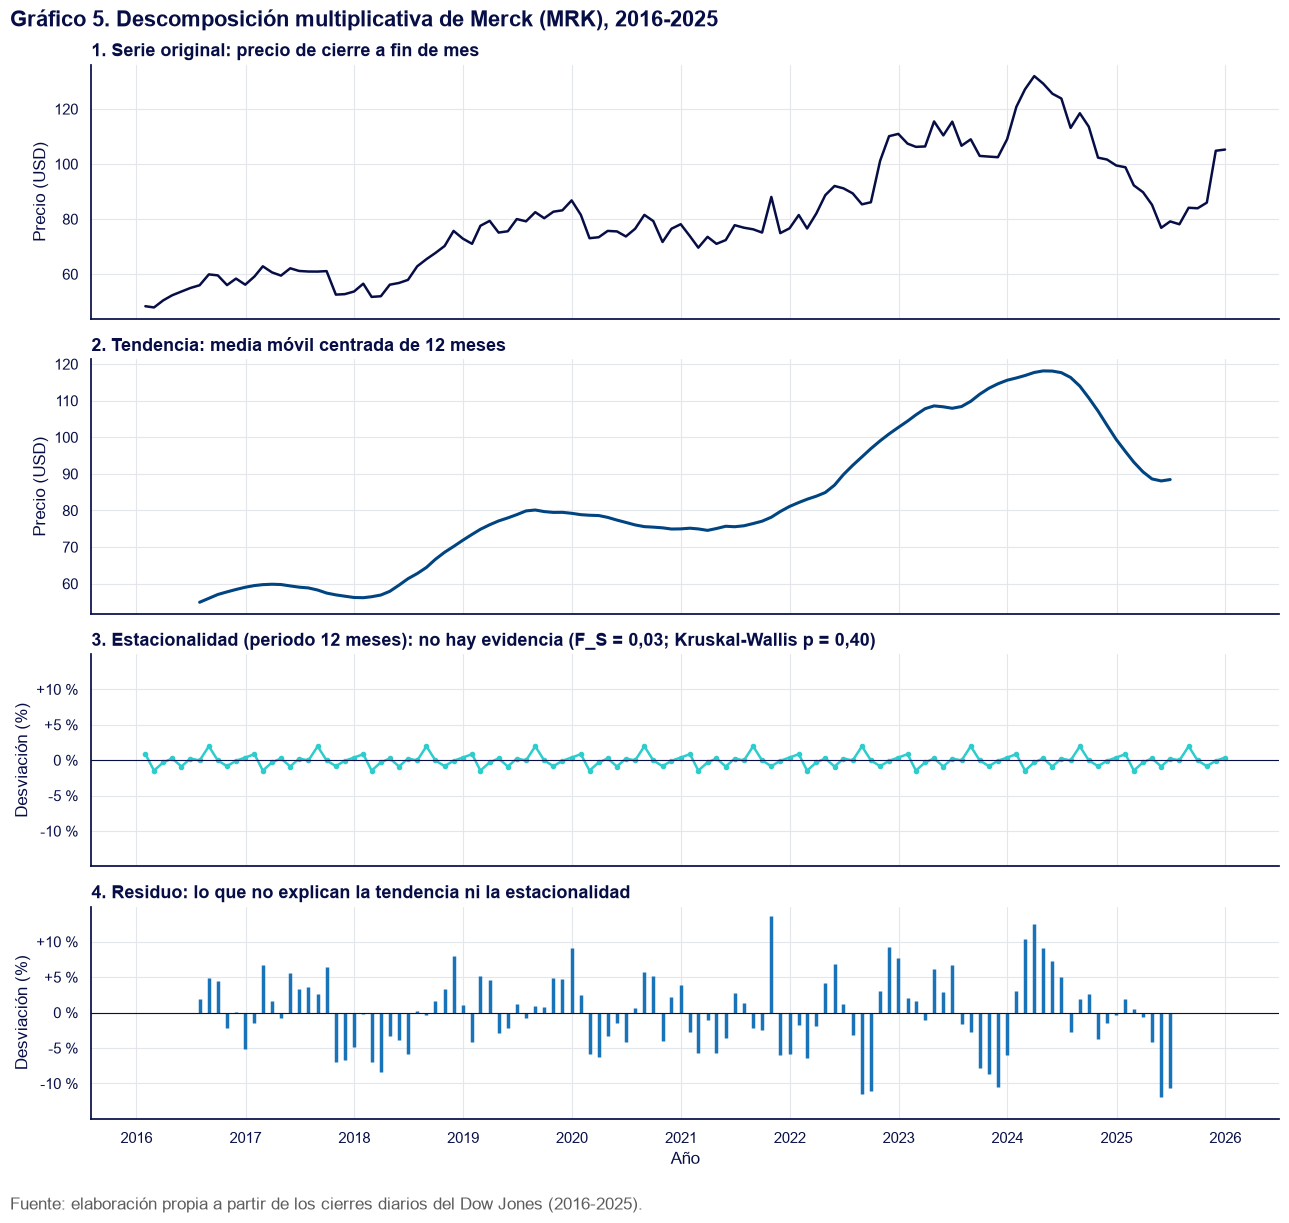

In [15]:
grafico_descomposicion("MRK", 5)

ANÁLISIS:

**Tendencia.** La de menor crecimiento: de 54,9 USD (julio de 2016) a 88,4 USD (junio de 2025), un 5,5 % anual. Es lateral hasta 2018, sube hasta 80,1 USD en agosto de 2019, se mantiene hasta 2021 y sube hasta su máximo de 118,1 USD en abril de 2024. Después cae un 25 % hasta 88,1 USD en mayo de 2025. En 2022 subió mientras Microsoft caía.

**Estacionalidad.** No hay: F_S = 0,03 y factores entre −1,5 % y +2,0 %. El panel 3 es ruido.

**Residuo.** Desviación típica del 5,3 %; solo el 7 % de los meses supera el 10 %. Los más extremos son octubre de 2021 (+13,6 %), marzo de 2024 (+12,4 %) y mayo de 2025 (−12,0 %). Destaca una racha positiva en la primera mitad de 2024, antes del máximo, y otra negativa en la primavera de 2025, durante la caída. Tampoco es ruido blanco (autocorrelación de 0,48; Ljung-Box p < 0,001).

**Límites.** El precio se recuperó hasta 105 USD a final de 2025, fuera del tramo con tendencia, así que no se puede saber si la caída ha terminado.

Guardado: c:\RETOS BDATA 3\26_27_R09_Azul_Claro\Graficos\descomposicion_06_msft.png


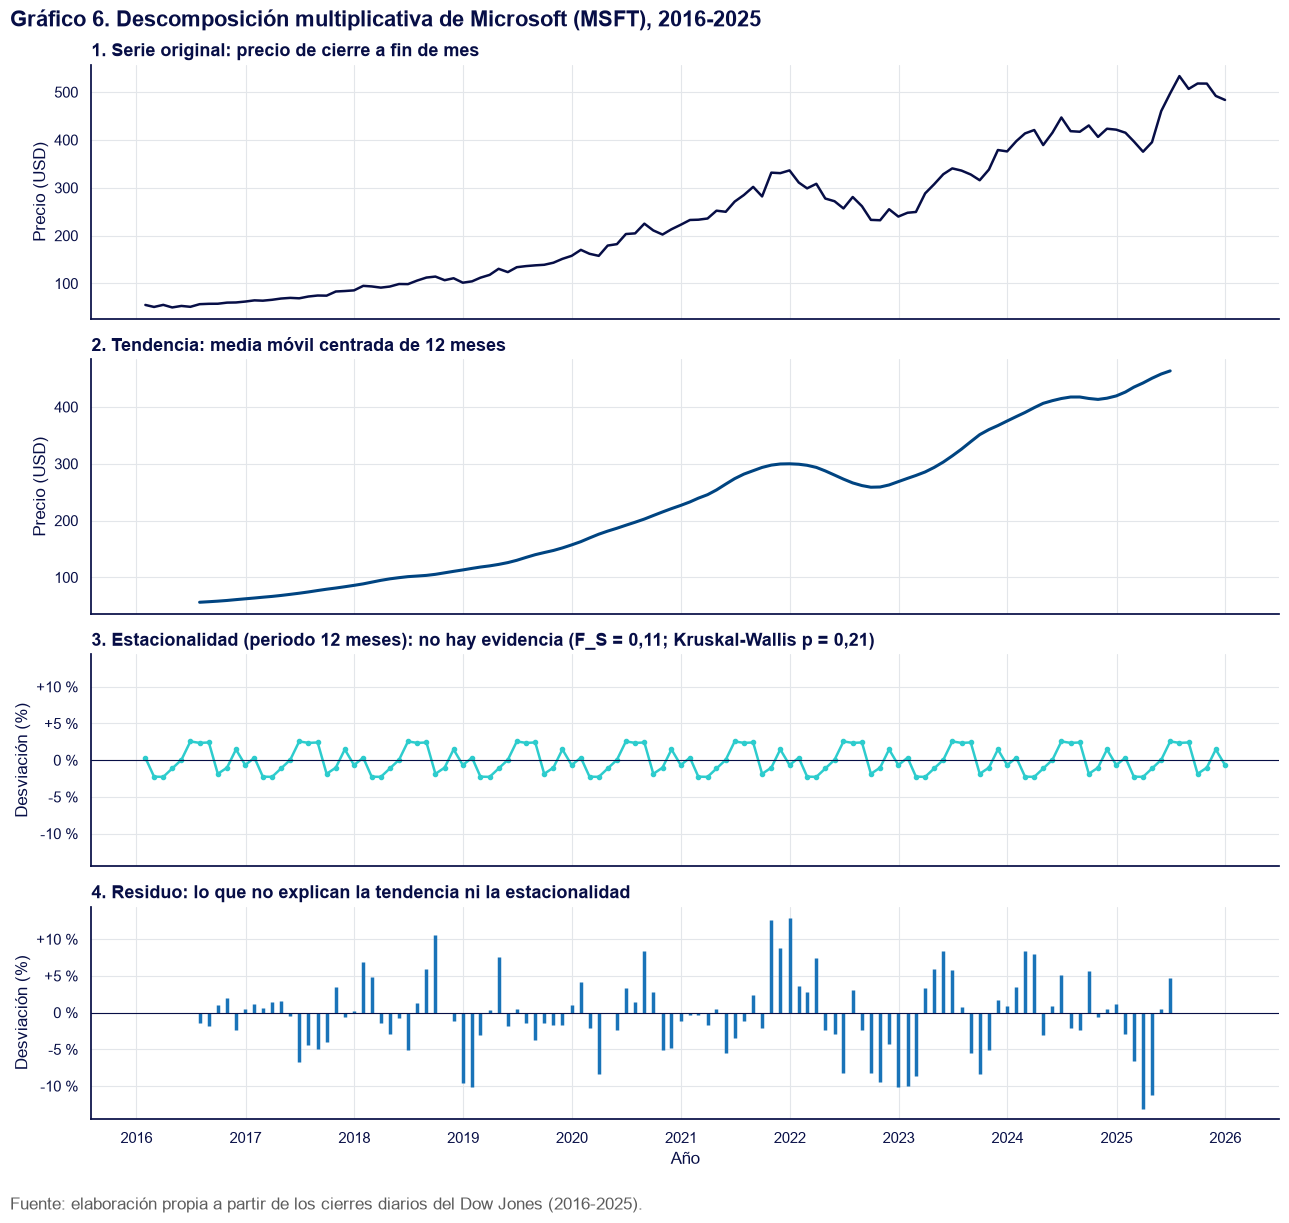

In [16]:
grafico_descomposicion("MSFT", 6)

ANÁLISIS:

**Tendencia.** La de mayor crecimiento y la más regular: de 56,2 USD (julio de 2016) a 463,4 USD (junio de 2025), un 26,7 % anual. Su única caída va de 299,9 USD en diciembre de 2021 a 258,7 USD en septiembre de 2022 (−13,7 %), coincidiendo con la subida de tipos. Después retoma la subida hasta su máximo.

**Estacionalidad.** No hay evidencia: F_S = 0,11, Kruskal-Wallis p = 0,21 y patrón distinto en cada mitad.

**Residuo.** El menor de los tres (5,2 %; solo el 6 % de los meses supera el 10 %), aunque crece con los años: del 1,8 % en 2016 al 6,9 % en 2025. Los meses más extremos son finales de 2021 (+12,6 % y +12,9 %), justo antes de la caída de 2022, y marzo y abril de 2025 (−13,1 % y −11,3 %). Autocorrelación de 0,50 en el retardo 1 (Ljung-Box p < 0,001).

## 6. Resumen y conclusión

In [17]:
def justificar_modelo(t):
    e = eleccion_modelo.loc[t]
    return (f"{e['decision']}. Amplitud frente a nivel: ρ = {fmt_es(e['rho_amplitud_nivel'], 2)} "
            f"(p {fmt_p(e['p_amplitud_nivel'])}); residuo aditivo frente a tendencia: "
            f"ρ = {fmt_es(e['rho_resid_aditivo'], 2)} (p {fmt_p(e['p_resid_aditivo'])}), "
            f"multiplicativo: ρ = {fmt_es(e['rho_resid_multiplicativo'], 2)} (p {fmt_p(e['p_resid_multiplicativo'])}). "
            f"Precios > 0 (mínimo {fmt_es(e['precio_min_usd'], 2)} USD).")


def justificar_periodo(t):
    ev, sem = evidencia.loc[t], semanal.loc[t]
    return (f"Datos mensuales: 12 meses por ciclo, {anios_completos} ciclos completos. "
            f"Sin efecto semanal (Kruskal-Wallis por día p = {fmt_es(sem['kruskal_dia_p'], 2)}). "
            f"Estacionalidad anual: {ev['veredicto'].lower()} (Kruskal-Wallis por mes p = {fmt_es(ev['kruskal_mes_p'], 2)}; "
            f"estabilidad entre mitades ρ = {fmt_es(ev['estabilidad_rho'], 2)}, p {fmt_p(ev['estabilidad_p'])}; "
            f"F_S = {fmt_es(ev['fuerza_estacional_FS'], 2)}).")


resumen = pd.DataFrame({
    "Activo": [f"{ACTIVOS[t]} ({t})" for t in ACTIVOS],
    "Modelo": ["Multiplicativo" if MODELO[t] == "multiplicative" else "Aditivo" for t in ACTIVOS],
    "Periodo": [f"{PERIODO} meses" for _ in ACTIVOS],
    "Estacionalidad": [evidencia.loc[t, "veredicto"] for t in ACTIVOS],
    "Justificación del modelo": [justificar_modelo(t) for t in ACTIVOS],
    "Justificación del periodo": [justificar_periodo(t) for t in ACTIVOS],
})
resumen.to_csv(RUTA_RESULTADOS / "descomposicion_resumen.csv", index=False, encoding="utf-8-sig")
with pd.option_context("display.max_colwidth", None):
    print(resumen.to_string(index=False))
print(f"\nGuardado: {RUTA_RESULTADOS / 'descomposicion_resumen.csv'}")

           Activo         Modelo  Periodo        Estacionalidad                                                                                                                                                                                                                                     Justificación del modelo                                                                                                                                                                                                                                 Justificación del periodo
Caterpillar (CAT) Multiplicativo 12 meses Débil, no concluyente Multiplicativo: los dos criterios indican que la amplitud crece con el nivel. Amplitud frente a nivel: ρ = 0,95 (p < 0,001); residuo aditivo frente a tendencia: ρ = 0,50 (p < 0,001), multiplicativo: ρ = 0,27 (p = 0,005). Precios > 0 (mínimo 62,24 USD). Datos mensuales: 12 meses por ciclo, 10 ciclos completos. Sin efecto semanal (Kruskal-Wallis por día p = 0,85). Esta

| Activo | Modelo | Periodo | Estacionalidad | Tendencia jul. 2016 → jun. 2025 | Residuo (desv. típica) |
|---|---|---|---|---|---|
| Caterpillar | Multiplicativo | 12 meses | Débil, no concluyente | ×5,2 (20,3 % anual) | 7,8 % |
| Merck | Multiplicativo | 12 meses | No hay evidencia | ×1,6 (5,5 % anual); −25 % desde abril de 2024 | 5,3 % |
| Microsoft | Multiplicativo | 12 meses | No hay evidencia | ×8,2 (26,7 % anual) | 5,2 % |

ANÁLISIS:

Los tres activos están dominados por la tendencia y ninguno tiene una estacionalidad fiable, así que en los modelos posteriores no hace falta incluir componentes estacionales. Se diferencian en el crecimiento y en la regularidad: Microsoft crece más y de forma más estable, Caterpillar crece a saltos y es el que más se separa de su tendencia, y Merck crece poco, termina a la baja y se comportó de forma distinta en 2022, algo útil para diversificar la cartera.

En los tres el residuo está autocorrelacionado: la descomposición clásica deja en él movimientos de medio plazo. Además, la media móvil no da tendencia para los seis primeros ni los seis últimos meses, y con 10 años de datos efectos estacionales pequeños (±2-4 %) no se distinguirían del ruido.